# 07 Image Model (Single-Mode)

**Question.** Was **the image itself** edited, by a face swap or a face attribute edit? The model gives each row a score `p_image_tampered` from 0 to 1. Caption-only edits count as *not edited*, because their pixels are untouched.

**What we do, step by step**

| Step | Section | What happens |
|---|---|---|
| 1 | 3 Prune the features | A lasso (L1) logistic regression keeps the useful engineered features from `04` |
| 2 | 4 Train on the kept features | Logistic Regression and XGBoost, same features and rows, with a confusion matrix for each |
| 3 | 5 Add CLIP image embeddings | The same two models again, with CLIP image embeddings added, and a confusion matrix for each |
| 4 | 6 Choose the baseline | The better of the two "+ embeddings" models on validation becomes the image-only baseline |

**Why add CLIP embeddings?** The multimodal models (`09`, `10`) use CLIP. Giving the image-only baseline the same image embeddings makes the comparison fair: a multimodal model can only beat it by using the caption.

**Rules.** Fit on `train_sample`, choose on `validation`, test once at the end (`RUN_TEST`). The model never sees captions, the caption embedding, image–caption similarities, file paths, ids or labels. The plain-ELA columns are left out as a dataset shortcut (`04`, section 3).

**Running it.** From `notebooks/`: `jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 07_image_model.ipynb` (about 4 minutes). Needs `02`, `04` and `05`.

## 0. Setup

In [1]:
import json
import os
import platform
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
import pyarrow.parquet as pq
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, roc_auc_score
from sklearn.model_selection import GroupKFold

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

# The notebook runs from notebooks/, so the shared code in src/ is one level up
PROJECT_ROOT = Path("..").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from huggingface_hub import hf_hub_download
from src.evaluation import best_f1_threshold, binary_metrics, detection_rate_by_type
from src.feature_sets import feature_columns
from src.image_features import FILTER_COLUMNS
# Label rule, input check, the two classifiers and the selection rule (tested in tests/test_image_model.py)
from src.image_model import (RANDOM_STATE, check_model_inputs, image_tampered_from_fake_cls, make_classifiers,
                             make_l1, select_baseline)

REPO_ID = "rshaojimmy/DGM4"           # dataset on the Hugging Face Hub (raw metadata for the label check)
N_FOLDS = 5                           # cross-validation folds on train, grouped by article id
L1_C_GRID = (0.001, 0.01, 0.1, 1.0)   # lasso strengths tried (smaller C = more features set to zero)
L1_TOLERANCE = 0.005                  # keep the strongest pruning whose CV AUC is within this of the best
TARGET_FPR = 0.01                     # the strict threshold flags 1% of untouched validation images

# The test split is used only in section 7 (Test), after the model and thresholds are fixed on validation
RUN_TEST = False

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"        # splits written by 02
FEATURES_DIR = PROJECT_ROOT / "data" / "features"          # feature groups written by 04 and 05
PREDICTIONS_DIR = PROJECT_ROOT / "results" / "predictions" # outputs shared with the team
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)

run_info = {"random_state": RANDOM_STATE, "python": platform.python_version(), "scikit-learn": sklearn.__version__,
            "xgboost": xgboost.__version__, "pandas": pd.__version__, "numpy": np.__version__}
sns.set_theme(style="whitegrid")
run_info

{'random_state': 4012,
 'python': '3.11.18',
 'scikit-learn': '1.9.1',
 'xgboost': '3.2.0',
 'pandas': '3.1.1',
 'numpy': '2.4.6'}

## 1. Labels

`image_tampered = 1` if `fake_cls` contains `face_swap` or `face_attribute`, else 0. The cell checks that this matches `02`'s `image_fake` on every row.

In [2]:
SPLITS = ["train_sample", "validation", "test"]                    # the three sets the model uses
OFFICIAL = {"train": "train", "validation": "val", "test": "test"}  # processed name -> raw metadata file name

# 02's cleaned splits, plus the raw metadata files they came from (used to count raw rows and check row order)
data = {name: pd.read_parquet(PROCESSED_DIR / f"{name}.parquet") for name in ["train", *SPLITS]}
raw = {name: pd.read_json(hf_hub_download(REPO_ID, f"metadata/{f}.json", repo_type="dataset"))
       for name, f in OFFICIAL.items()}

# Build the image label from the tags and check it against 02's image_fake
for df in [*data.values(), *raw.values()]:
    df["image_tampered"] = df["fake_cls"].map(image_tampered_from_fake_cls).astype("int8")
for name, df in data.items():
    assert (df["image_tampered"] == df["image_fake"]).all(), f"{name}: image label disagrees with 02"

# row_id is positional (e.g. test_000123 is the 124th row), so check that 02's rows are exactly the metadata rows,
# in the same order, after its de-duplication. Otherwise predictions would join to the wrong rows.
key = ["id", "text", "image", "fake_cls"]
for name, df in raw.items():
    expected = df.drop_duplicates(key).reset_index(drop=True)
    assert len(expected) == len(data[name]) and all(
        (expected[c].to_numpy() == data[name][c].to_numpy()).all() for c in key
    ), f"{name}: rows differ from metadata/{OFFICIAL[name]}.json"
print("image_tampered matches 02's image_fake on every row; 02's rows match the metadata files in order")

image_tampered matches 02's image_fake on every row; 02's rows match the metadata files in order


## 2. Load the Features

- **Engineered features** from `04`: 30 from the `image` group (plain-ELA columns removed) + 10 from `image_filters` = **40 candidates**
- **CLIP image embeddings** from `05`: 768 numbers per image (`clip_img_*`). The caption embedding in the same file is not loaded.

Each model is fit once per distinct `train_sample` image and scored on every validation row.

In [3]:
def emb_path(split):
    return FEATURES_DIR / f"clip_emb_{split}.parquet"


EMBEDDINGS = [c for c in pq.read_schema(emb_path("validation")).names if c.startswith("clip_img_")]


def load_split(split):
    df = data[split].merge(pd.read_parquet(FEATURES_DIR / f"image_{split}.parquet"), on="row_id", how="left")
    df = df.merge(pd.read_parquet(FEATURES_DIR / f"image_filters_{split}.parquet"), on="row_id", how="left")
    df = df.merge(pd.read_parquet(emb_path(split), columns=["row_id", *EMBEDDINGS]), on="row_id", how="left")
    assert len(df) == len(data[split]) and df["row_id"].is_unique, f"{split}: rows changed in the join"
    assert df[EMBEDDINGS].notna().all().all(), f"{split}: rows without a CLIP embedding"
    return df


tables = {split: load_split(split) for split in SPLITS}
train = tables["train_sample"].drop_duplicates("image").reset_index(drop=True)  # one row per distinct image
val, test = tables["validation"], tables["test"]
y_train, y_val = train["image_tampered"].to_numpy(), val["image_tampered"].to_numpy()
groups = train["id"].to_numpy()  # article id: all versions of an article stay in one fold

# 30 columns from the image group (shortcuts dropped) + 10 from image_filters
ENGINEERED = check_model_inputs(feature_columns(train, "img_"))
assert set(FILTER_COLUMNS) <= set(ENGINEERED) and len(ENGINEERED) == 40
check_model_inputs(EMBEDDINGS)
print(f"train_sample: {len(train):,} distinct images | validation: {len(val):,} rows | test: {len(test):,} rows")
print(f"{len(ENGINEERED)} engineered candidates, {len(EMBEDDINGS)} CLIP image-embedding columns")
print("Missing values in engineered features (train):", int(train[ENGINEERED].isna().sum().sum()))

train_sample: 44,857 distinct images | validation: 22,126 rows | test: 50,705 rows
40 engineered candidates, 768 CLIP image-embedding columns
Missing values in engineered features (train): 0


## 3. Step 1: Prune the Features with a Lasso (L1)

Some engineered features repeat each other. A lasso logistic regression gives weak or duplicate features a weight of exactly 0, and we drop those.
- The penalty strength `C` is chosen by 5-fold cross-validation on `train_sample` (grouped by article): the smallest `C` whose AUC is within 0.005 of the best.
- The features left are `ENGINEERED_KEPT`, used by both models from here on.

In [4]:
folds = list(GroupKFold(n_splits=N_FOLDS).split(train, y_train, groups))


def grouped_cv_auc(model, cols):
    # Mean AUC over the article-grouped folds of train_sample
    X = train[cols]
    return float(np.mean([roc_auc_score(y_train[va], clone(model).fit(X.iloc[tr], y_train[tr]).predict_proba(X.iloc[va])[:, 1])
                          for tr, va in folds]))


l1_cv = pd.DataFrame([{"C": C, "cv AUC": grouped_cv_auc(make_l1(C), ENGINEERED)} for C in L1_C_GRID])
for C in L1_C_GRID:
    l1_cv.loc[l1_cv["C"] == C, "features kept"] = int((make_l1(C).fit(train[ENGINEERED], y_train)[-1].coef_ != 0).sum())
L1_C = float(l1_cv.loc[l1_cv["cv AUC"] >= l1_cv["cv AUC"].max() - L1_TOLERANCE, "C"].min())
display(l1_cv.round(4))
print("Chosen C:", L1_C)

lasso = make_l1(L1_C).fit(train[ENGINEERED], y_train)
weights = pd.Series(lasso[-1].coef_[0], index=ENGINEERED, name="weight (standardised)")
ENGINEERED_KEPT = weights[weights != 0].index.tolist()
DROPPED = weights[weights == 0].index.tolist()
print(f"Kept {len(ENGINEERED_KEPT)} of {len(ENGINEERED)} engineered features; dropped {len(DROPPED)}:")
print(", ".join(DROPPED) if DROPPED else "(none)")

,C,cv AUC,features kept
0,0.001,0.5906,4.0
1,0.010,0.6058,19.0
2,0.100,0.6263,34.0
3,1.000,0.6272,40.0


Chosen C: 0.1


Kept 34 of 40 engineered features; dropped 6:
img_ela_ratio_mean, img_ela_ratio_spread, img_lap_ratio_min, img_lap_ratio_largest, img_lap_ratio_spread, img_noise_face_min


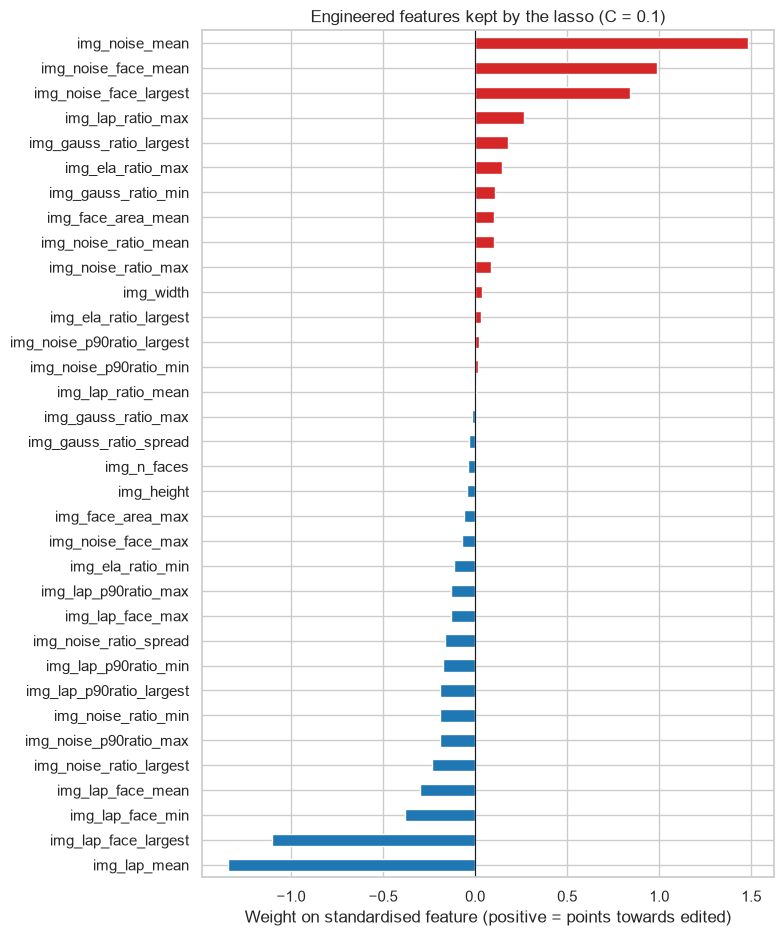

In [5]:
kept = weights[ENGINEERED_KEPT].sort_values()
fig, ax = plt.subplots(figsize=(8, max(3, 0.28 * len(kept))))
kept.plot.barh(ax=ax, color=np.where(kept > 0, "tab:red", "tab:blue"))
ax.axvline(0, color="k", lw=0.8)
ax.set_title(f"Engineered features kept by the lasso (C = {L1_C:g})")
ax.set_xlabel("Weight on standardised feature (positive = points towards edited)")
plt.tight_layout()
plt.show()

**Reading the output.** `C = 0.1` keeps **34 of the 40** features with almost no loss in cross-validated AUC (0.626 vs 0.627 with all 40). It drops 6 features from the original `image` group: `img_ela_ratio_mean`, `img_ela_ratio_spread`, `img_lap_ratio_min`, `img_lap_ratio_largest`, `img_lap_ratio_spread` and `img_noise_face_min`. All 10 new `image_filters` features are kept.

Read the chart with care. The biggest weights come in near-duplicate pairs with opposite signs (for example, whole-image noise +1.5 and whole-image Laplacian −1.3), so the model is using the *gap* between them.

## 4. Step 2: Train Logistic Regression and XGBoost on the Kept Features

Both models get exactly the same 34 features and rows. Settings are fixed (`src/image_model.make_classifiers`):
- **Logistic Regression:** fill missing values with the training median → scale → logistic regression
- **XGBoost:** fill missing values with the training median → 300 trees, depth 4

**Confusion matrix:** for each model, the validation images it calls *edited* or *untouched*, using that model's best-F1 threshold (chosen on validation).

Kept features (34), Logistic Regression: validation ROC-AUC = 0.6302
Kept features (34), XGBoost: validation ROC-AUC = 0.6520


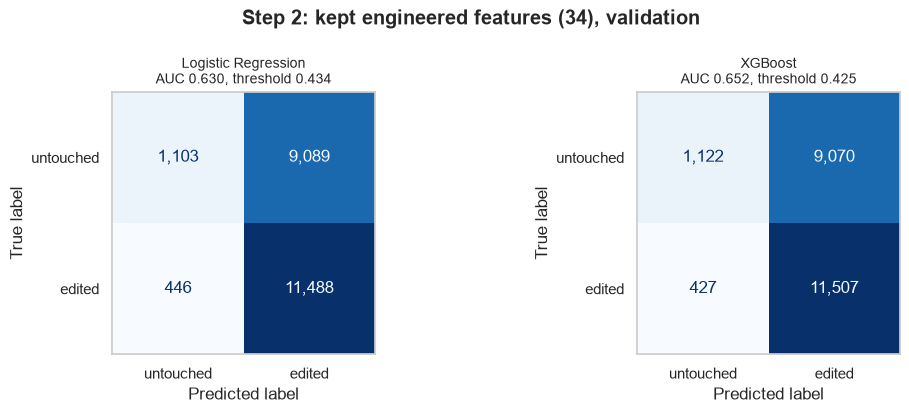

In [6]:
def fit_and_score(cols):
    # Fit both classifiers on the same train rows and columns; return the fitted models and validation AUCs
    models, aucs = {}, {}
    for name, model in make_classifiers().items():
        models[name] = model.fit(train[cols], y_train)
        aucs[name] = roc_auc_score(y_val, models[name].predict_proba(val[cols])[:, 1])
    return models, aucs


def show_confusion_matrices(models, cols, title):
    # One confusion matrix per model on validation, each at its own best-F1 threshold (chosen on validation)
    fig, axes = plt.subplots(1, len(models), figsize=(11, 4.2))
    for ax, (name, model) in zip(axes, models.items()):
        score = model.predict_proba(val[cols])[:, 1]
        threshold = best_f1_threshold(y_val, score)
        cm = confusion_matrix(y_val, score >= threshold)
        ConfusionMatrixDisplay(cm, display_labels=["untouched", "edited"]).plot(ax=ax, cmap="Blues", values_format=",",
                                                                                colorbar=False)
        ax.set_title(f"{name}\nAUC {roc_auc_score(y_val, score):.3f}, threshold {threshold:.3f}", fontsize=10)
        ax.grid(False)
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()


models_eng, auc_eng = fit_and_score(ENGINEERED_KEPT)
for name, auc in auc_eng.items():
    print(f"Kept features ({len(ENGINEERED_KEPT)}), {name}: validation ROC-AUC = {auc:.4f}")
show_confusion_matrices(models_eng, ENGINEERED_KEPT, f"Step 2: kept engineered features ({len(ENGINEERED_KEPT)}), validation")

**Reading the output.** On their own, the engineered features are weak: validation AUC **0.630** (Logistic Regression) and **0.652** (XGBoost).

The confusion matrices show why. To catch most edited images (11,488 and 11,507 of 11,934), both models have to call almost everything edited. Only about 1,100 of the 10,192 untouched images are correctly left alone. The features carry a real signal, but not enough to separate the two groups well. XGBoost is slightly better here, because it can combine weak cues.

## 5. Step 3: Add CLIP Image Embeddings and Train Again

The same two models and settings, now on the 34 kept features **plus** the 768 CLIP image-embedding numbers. Only the inputs change.

Kept features + embeddings (802), Logistic Regression: validation ROC-AUC = 0.8146 (+0.1845 vs step 2)
Kept features + embeddings (802), XGBoost: validation ROC-AUC = 0.7714 (+0.1195 vs step 2)


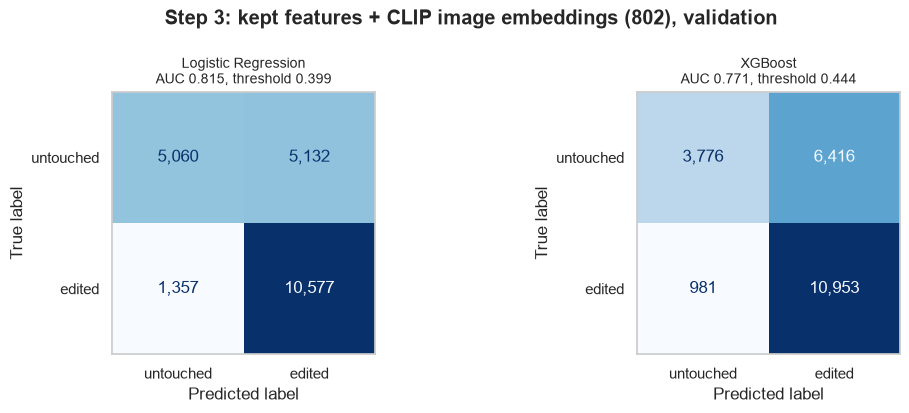

In [7]:
ENGINEERED_PLUS_EMB = check_model_inputs(ENGINEERED_KEPT + EMBEDDINGS)
models_emb, auc_emb = fit_and_score(ENGINEERED_PLUS_EMB)
for name, auc in auc_emb.items():
    print(f"Kept features + embeddings ({len(ENGINEERED_PLUS_EMB)}), {name}: validation ROC-AUC = {auc:.4f} "
          f"({auc - auc_eng[name]:+.4f} vs step 2)")
show_confusion_matrices(models_emb, ENGINEERED_PLUS_EMB,
                        f"Step 3: kept features + CLIP image embeddings ({len(ENGINEERED_PLUS_EMB)}), validation")

**Reading the output.** Adding the CLIP image embeddings helps both models a lot:
- **Logistic Regression:** 0.630 → **0.815** (+0.185)
- **XGBoost:** 0.652 → **0.771** (+0.120)

The confusion matrices improve the same way. Logistic Regression now correctly leaves **5,060** untouched images alone (up from 1,103) and still catches **10,577** of 11,934 edited ones. XGBoost leaves 3,776 alone and catches 10,953.

With embeddings, Logistic Regression moves ahead. 768 dense embedding numbers suit a linear model, while shallow trees with fixed settings use them less well.

## 6. Step 4: Choose the Baseline

We compare the two "+ embeddings" models on validation ROC-AUC and keep **the higher one** as the image-only baseline. If they tie (same AUC to 3 decimals), we keep Logistic Regression because it is simpler.

For the chosen model we also fix two thresholds on validation:
- **best F1**, the main operating point
- **1% false alarms**, a strict operating point that flags only 1% of untouched images

In [8]:
comparison = pd.DataFrame({f"step 2: kept features ({len(ENGINEERED_KEPT)})": auc_eng,
                           f"step 3: + embeddings ({len(ENGINEERED_PLUS_EMB)})": auc_emb}).T
comparison.columns.name = "validation ROC-AUC"
display(comparison.round(4))

SELECTED = select_baseline(auc_emb)
baseline = models_emb[SELECTED]
print(f"Image-only baseline: {SELECTED} + CLIP image embeddings (validation AUC {auc_emb[SELECTED]:.4f})")

val["p_image_tampered"] = baseline.predict_proba(val[ENGINEERED_PLUS_EMB])[:, 1]
threshold_f1 = best_f1_threshold(y_val, val["p_image_tampered"])
# 99th percentile of untouched-image scores: only 1% of genuine validation images score above it
threshold_fpr1 = float(np.quantile(val.loc[y_val == 0, "p_image_tampered"], 1 - TARGET_FPR))
CONFIG = {"classifier": SELECTED, "features": "engineered + CLIP image embeddings", "l1_C": L1_C,
          "engineered_kept": ENGINEERED_KEPT, "engineered_dropped": DROPPED, "n_inputs": len(ENGINEERED_PLUS_EMB),
          "threshold_f1": threshold_f1, "threshold_fpr1": threshold_fpr1}
val_metrics = pd.DataFrame({"best-F1 threshold": binary_metrics(y_val, val["p_image_tampered"], threshold_f1),
                            "1% false-alarm threshold": binary_metrics(y_val, val["p_image_tampered"], threshold_fpr1)}).T
display(val_metrics.round(3))
print("Share of each type called edited (best-F1 threshold):")
display(detection_rate_by_type(val, val["p_image_tampered"], threshold_f1).round(3))

validation ROC-AUC,Logistic Regression,XGBoost
step 2: kept features (34),0.6302,0.6520
step 3: + embeddings (802),0.8146,0.7714


Image-only baseline: Logistic Regression + CLIP image embeddings (validation AUC 0.8146)


,AUC,PR-AUC,EER,ACC,Precision,Recall,F1,threshold
best-F1 threshold,0.815,0.845,0.272,0.707,0.673,0.886,0.765,0.399
1% false-alarm threshold,0.815,0.845,0.272,0.581,0.964,0.231,0.373,0.918


Share of each type called edited (best-F1 threshold):


,flagged_rate,n
fake_cls,,
text_attribute,0.461,825
text_swap,0.504,1894
orig,0.508,7473
face_swap&text_attribute,0.859,533
face_swap,0.864,4788
face_swap&text_swap,0.876,1163
face_attribute&text_swap,0.898,964
face_attribute,0.912,3999
face_attribute&text_attribute,0.922,487


**Reading the output.**
- **Logistic Regression + CLIP image embeddings has the higher validation AUC (0.815 vs 0.771), so it is our image-only baseline.**
- **At the best-F1 threshold (0.399):** precision 0.673, recall 0.886, F1 0.765. It catches 86–92% of every face-edit type. It flags caption-only edits (`text_swap`, `text_attribute`) about as often as untouched originals, as expected for a model that only looks at pixels.
- **At the strict threshold (0.918),** only 1% of untouched images are flagged, and it catches 23% of edited ones.

## 7. Test

Test labels are used only here, with the model and thresholds fixed in section 6. Set `RUN_TEST = True` once, at the end of the project.

In [9]:
test["p_image_tampered"] = baseline.predict_proba(test[ENGINEERED_PLUS_EMB])[:, 1]
if RUN_TEST:
    y_test = test["image_tampered"].to_numpy()
    majority = int(y_train.mean() >= 0.5)  # most common training label
    results_test = pd.DataFrame({
        f"majority class (always {majority})": binary_metrics(y_test, np.full(len(y_test), float(majority))),
        f"{SELECTED}, F1 threshold": binary_metrics(y_test, test["p_image_tampered"], threshold_f1),
        f"{SELECTED}, 1% FPR threshold": binary_metrics(y_test, test["p_image_tampered"], threshold_fpr1),
    }).T
    display(results_test.round(4))
    display(detection_rate_by_type(test, test["p_image_tampered"], threshold_f1).round(3))
else:
    print("RUN_TEST is False: test predictions are saved, but test labels are not evaluated.")

RUN_TEST is False: test predictions are saved, but test labels are not evaluated.


## 8. Save Predictions

Scores for every row of `train_sample`, `validation` and `test`, keyed by `row_id`, in the files `11` and `reports/compare_models.py` read: `results/predictions/image_model_*.parquet` (columns `row_id, split, id, image_tampered, p_image_tampered, p_image_fake`), plus the thresholds, metrics and config. `train_sample` scores are **out-of-fold** (each image is scored by a model that did not see its article).

In [10]:
# Out-of-fold scores for train_sample images, copied to every train_sample row of the image
oof = np.zeros(len(train))
for tr, va in folds:
    model = clone(make_classifiers()[SELECTED]).fit(train.loc[tr, ENGINEERED_PLUS_EMB], y_train[tr])
    oof[va] = model.predict_proba(train.loc[va, ENGINEERED_PLUS_EMB])[:, 1]
train_rows = tables["train_sample"]
train_rows["p_image_tampered"] = train_rows["image"].map(pd.Series(oof, index=train["image"]))
print(f"train_sample out-of-fold AUC (rows): {roc_auc_score(train_rows['image_tampered'], train_rows['p_image_tampered']):.4f}")

for name, split, df in [("train_sample_oof", "train_sample", train_rows), ("validation", "validation", val), ("test", "test", test)]:
    p = df["p_image_tampered"].to_numpy()
    frame = pd.DataFrame({"row_id": df["row_id"].to_numpy(), "split": split, "id": df["id"].to_numpy(),
                          "image_tampered": df["image_tampered"].to_numpy(), "p_image_tampered": p, "p_image_fake": p})
    # Guard against silent errors: one row per input row, in 02's order, with valid probabilities
    assert frame["row_id"].tolist() == data[split]["row_id"].tolist()
    assert frame["p_image_tampered"].between(0, 1).all() and frame["p_image_tampered"].notna().all()
    path = PREDICTIONS_DIR / f"image_model_{name}.parquet"
    frame.to_parquet(path, index=False)
    print(f"{path.relative_to(PROJECT_ROOT)}  {frame.shape}")

pd.Series({"image_fake": threshold_f1, "image_fake_fpr1": threshold_fpr1}, name="threshold").to_frame().to_csv(
    PREDICTIONS_DIR / "image_model_thresholds.csv")
metrics = comparison.assign(split="validation")
if RUN_TEST:
    metrics = pd.concat([metrics, results_test.assign(split="test")])
metrics.to_csv(PREDICTIONS_DIR / "image_model_metrics.csv")
with open(PREDICTIONS_DIR / "image_model_config.json", "w") as f:
    json.dump({**run_info, **CONFIG, "validation_auc": {"engineered": auc_eng, "engineered_plus_embeddings": auc_emb},
               "l1_cv": l1_cv.to_dict("records"), "n_folds": N_FOLDS, "run_test": RUN_TEST}, f, indent=2, default=float)
print("saved thresholds, metrics and config to", PREDICTIONS_DIR.relative_to(PROJECT_ROOT))

train_sample out-of-fold AUC (rows): 0.8194
results/predictions/image_model_train_sample_oof.parquet  (49943, 6)
results/predictions/image_model_validation.parquet  (22126, 6)
results/predictions/image_model_test.parquet  (50705, 6)
saved thresholds, metrics and config to results/predictions


# Summary

1. **Pruned the features:** a lasso kept 34 of the 40 engineered features (C = 0.1), with no loss in cross-validated AUC.
2. **Trained on the kept features:** Logistic Regression 0.630 and XGBoost 0.652 validation AUC. The classical cues work, but weakly.
3. **Added CLIP image embeddings:** Logistic Regression 0.815 and XGBoost 0.771. Both improved strongly.
4. **Chose the baseline:** Logistic Regression + CLIP image embeddings has the higher validation AUC, so **it is our image-only baseline** (thresholds 0.399 best-F1, 0.918 for 1% false alarms).

| Validation ROC-AUC | Logistic Regression | XGBoost |
|---|---|---|
| Kept engineered features (34) | 0.630 | **0.652** |
| + CLIP image embeddings (802) | **0.815** | 0.771 |

- **Not used:** captions, the caption embedding, image–caption similarities, paths, ids, labels, and the plain-ELA shortcut features.
- **Test set:** not used for any choice (`RUN_TEST = False`).
- **Saved:** predictions in `results/predictions/image_model_*`, read by `11`.